# IS 4487 Assignment 14: Exploring APIs with yfinance

In this assignment, you will:
- Choose an industry you're interested in (such as tech, airlines, or retail)
- Use the `yfinance` Python package as an API to collect historical stock price data
- Clean and prepare the data for analysis
- Explore trends, volatility, and relationships between companies
- Summarize your findings and recommendation in a business memo

## Why This Matters

APIs (Application Programming Interfaces) allow businesses to pull live, real-world data from external sources directly into their analytics tools. Financial analysts, investment firms, and business leaders use APIs like `yfinance` to monitor company performance, assess market trends, and build models based on dynamic data.

This assignment helps you gain hands-on experience with one of the most common API workflows in business analytics: fetching, cleaning, analyzing, and interpreting financial data to support better decision-making.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_14_api.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Step 1: Choose an Industry and Find Company Ticker Symbols

Visit the following website to explore U.S. stock sectors and industries:  
https://www.tradingview.com/markets/stocks-usa/sectorandindustry-sector/

### Do the following
Choose one industry you are interested in (for example: Airlines, Technology, Fast Food, Retail, Energy, etc.).  
Write the names and ticker symbols of 4 public companies in that industry.

**Example:**
- Industry: Technology  
- Tickers: AAPL, MSFT


In [1]:
# Replace this list with your selected tickers
tickers = ['JPM', 'BAC', 'GS', 'MS']

## Step 2: Use yfinance to Collect Historical Stock Data

Follow the steps below to use the `yfinance` API to collect historical stock price data.

### Do the following

1. Make sure the `yfinance` package is installed by running the code cell below.
2. Import any additional Python libraries that you might need to explore or visualize the data.
3. Use the `yf.download()` function to pull **5 years of daily adjusted close prices** for the companies you selected in Step 1.
    - Choose a start date and an end date that span the past 5 years (e.g., `"2020-01-01"` to `"2025-12-31"`).
    - Only select the **'High'** column, which represents the daily high
4. Preview the first few rows of the dataset using `.head()` to confirm that the data has loaded correctly.



In [2]:
# Import necessary libraries
!pip -q install yfinance

import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
# Download adjusted daily high prices
df = yf.download(tickers,  start='2021-11-05', end='2026-11-05', auto_adjust=True)['High']

[*********************100%***********************]  4 of 4 completed


In [4]:
df.head()

Ticker,BAC,GS,JPM,MS
Date,,,,
2021-11-05,42.310252,367.152050,150.243351,87.040272
2021-11-08,42.292558,366.443328,150.976543,86.886628
2021-11-09,41.903252,361.066097,148.812387,85.614914
2021-11-10,42.044818,359.267659,149.236382,85.026000
2021-11-11,42.372183,357.682000,148.997907,84.761408


## Step 3: Clean the Data

The data you pulled may contain missing values.

### Do the following

1. Check the dataset for missing values using `.isnull().sum()`.
2. Fill any missing values using a forward fill method.
3. Recheck for missing values to confirm they have been handled.



In [6]:
print("Missing values before cleaning:")
print(df.isnull().sum())

df = df.ffill()

print("\nMissing values after cleaning:")
print(df.isnull().sum())


Missing values before cleaning:
Ticker
BAC    0
GS     0
JPM    0
MS     0
dtype: int64

Missing values after cleaning:
Ticker
BAC    0
GS     0
JPM    0
MS     0
dtype: int64


## Step 4: Calculate Daily Returns

To better understand price movement, we will calculate the daily percentage change for each stock.

### Do the following

1. Use the `.pct_change()` method to calculate daily returns.
2. Drop any rows with missing values that may result from this calculation.
3. Preview the returns DataFrame to confirm it's correct.


In [7]:
returns = df.pct_change().dropna()

display(returns.head())


Ticker,BAC,GS,JPM,MS
Date,,,,
2021-11-08,-0.000418,-0.001930,0.004880,-0.001765
2021-11-09,-0.009205,-0.014674,-0.014334,-0.014636
2021-11-10,0.003378,-0.004981,0.002849,-0.006879
2021-11-11,0.007786,-0.004414,-0.001598,-0.003112
2021-11-12,-0.007517,0.003319,-0.005573,0.005840


## Step 5: Explore the Data Visually and Statistically

In this step, you will create visualizations and metrics to help understand stock behavior. Don’t interpret or explain anything here — just create the outputs so you can use them in your reflection later.

### Do the following
1. Create a line chart showing stock prices over the 5-year period.
2. Calculate the standard deviation of daily returns for each stock (volatility).
3. Create a correlation matrix of the daily returns between companies.




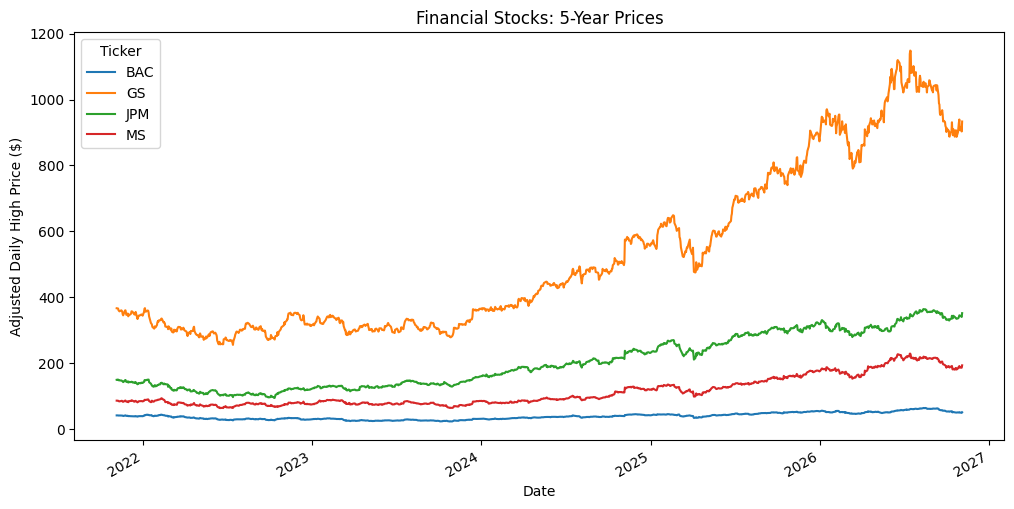

Daily Volatility:
Ticker
BAC    1.59
GS     1.68
JPM    1.42
MS     1.73
dtype: float64

Correlation Matrix:


Ticker,BAC,GS,JPM,MS
Ticker,,,,
BAC,1.00,0.71,0.79,0.74
GS,0.71,1.00,0.73,0.85
JPM,0.79,0.73,1.00,0.71
MS,0.74,0.85,0.71,1.00


In [8]:
# 1. Stock price trends
df.plot(figsize=(12, 6), title='Financial Stocks: 5-Year Prices')
plt.xlabel('Date')
plt.ylabel('Adjusted Daily High Price ($)')
plt.show()

# 2. Volatility
print("Daily Volatility:")
print((returns.std() * 100).round(2))

# 3. Correlation matrix
print("\nCorrelation Matrix:")
display(returns.corr().round(2))


## Step 6: Write a Stakeholder Recommendation Memo

Now that you’ve completed your analysis, it’s time to turn your work into a clear, professional memo for a business audience.

### Scenario

You’ve been asked by a stakeholder (an investor, executive, or client) to evaluate whether it's a good time to invest in a particular industry. They’ve asked you to use recent stock performance data from several leading companies in that industry to help guide their decision.

### Your Task

Use the results from your code in Steps 2–5 to write a **multi-paragraph business memo** that:

1. **Introduces the industry you analyzed** and names the companies you included.
2. **Summarizes major trends** you observed in the stock prices over the last 5 years.
3. **Discusses key metrics**, such as volatility and correlations between companies.
4. **Presents your investment recommendation** — based on your evidence — and explains why you would or wouldn’t advise investing in this industry now.
5. **Suggests future analytics or data sources** that could strengthen or update your recommendation going forward.

This final section should show that you understand how real-world decisions evolve. Think about:
- What **additional data** might help (e.g., earnings reports, economic indicators, sentiment analysis)?
- What **types of models** could be applied (e.g., forecasting, classification, risk modeling)?
- How often should the analysis be updated?

### Format & Expectations

- Write **2–4 paragraphs** in business memo format (not bullet points).
- Use **specific, data-driven evidence** from your own analysis.
- Keep your writing professional and clear — imagine your reader is a client or executive, not a data analyst.
- Your memo should be written **entirely in your own words**. Do not copy from examples, online sources, or AI tools. Your writing should reflect your understanding and your interpretation of the results.
- You do not need to include charts in the memo — the code cells above already display them.



### ✍️ Add memo here:

Memo:
I analyzed the Finance industry and the companies I picked are Goldman Sachs (GS), JPMorgan Chase (JPM), Morgan Stanley (MS), Bank of America (BAC). I observed the historical price growth over the last 5 years (November 2021 - November 2026). To summarize the major trends I found, I found that Goldman Sachs had the highest price increase of 154.21%, after that was JPMorgan Chase with a price of 134.51%, Morgan Stanley with a price of 123.01%, and lastly was Bank of American with a price of 22.33%. Thus, Goldman Sachs did the best in historical price growth.

Based on volatility, I found that Morgan Stanley had the highest volatility daily at 1.73% and JPMorgan Chase had the lowest at 1.42% which means it had the least variation. I also noticed that all of the companies had a positive correlation. Goldman Sachs and Morgan had the strongest correlation of 0.85 which means their stock prices aligned with company.

Based on my evidence, for stakeholders, I would recommend investing in JPMorgan Chase if you want to focus on historical growth and having a low volatility. Even though Goldamn Sachs had the highest price growth, JPMorgan Chase did well in both price growth and volatility. I would advise not to invest into only these companies because they're all strongly correlated, so risks could impact the financial industry as a whole.

Before making an investment decision, I would suggest analyzing other factors rather than just pricI would look at other factors like profits, interest rates or market conditions before deciding on one or the other. It would also be nice to compare the companies with other industries and to check their portfolio diversification. All in all, there are certainly companies that stand out more than others, but I would definitely do more research before getting fully involved.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_14_api.ipynb"